# 6주차 이론 예제 — 워크북 코드를 미리 실행해 보기

**인공지능과 데이터 활용 · 고객 리뷰 데이터의 가공 및 분석**

이론 시간에 **노션 본문 순서대로 한 셀씩 실행하며** 설명하는 노트북입니다. 워크북 0~4에서 쓰는 코드를 아주 작은 예제로 쪼개
"이 한 줄이 무엇을 하는지"를 직접 확인합니다. 외부 데이터 없이 바로 실행됩니다(약 20초).

| 노션 이론 | 예제 |
|---|---|
| 공통 기초 (3장 앞) | 예제 1. 도구 상자 가져오기 — import와 주석<br>예제 2. 후기 한 줄 다루기 — 문자열<br>예제 3. 여러 후기 다루기 — 리스트와 반복문<br>예제 4. 별점을 라벨로 바꾸기 — 딕셔너리와 f-문자열<br>예제 5. 판단을 함수로 묶기 — def와 조건 표현식<br>예제 6. 후기 표 만들기 — DataFrame·열·.str·새 열<br>예제 7. 조건으로 후기 고르기 — 불리언 필터<br>예제 8. 열 전체 값 바꾸기 — map·lambda·np.where<br>예제 9. 묶어서 세고 평균 내기 — value_counts·groupby·crosstab |
| 3.1 텍스트 데이터와 감성분석 | 예제 10. 별점으로 라벨 붙이기와 라벨 잡음 |
| 3.2 감성데이터 수집 (워크북 0) | 예제 11. 탭으로 구분된 원자료 읽기 — read_csv 옵션<br>예제 12. 복사·도배 후기 걸러내기 — 중복 제거<br>예제 13. 개인정보 의심 문장 걸러내기 — 정규표현식 search<br>예제 14. 별점마다 같은 수 뽑기 — 층화 추출과 난수 시드<br>예제 15. 해시 동작 원리 — MD5 파일 지문 |
| 3.3 텍스트 전처리와 탐색 (워크북 1) | 예제 16. 공백·반복 글자 정리하기 — re.sub<br>예제 17. 어절 꺼내 빈도 세기 — re.findall·Counter |
| 3.4 수작업 키워드 규칙 분류 (워크북 2) | 예제 18. 단어가 몇 개 들어 있나 세기 — in과 sum<br>예제 19. 키워드 규칙 v1과 실패 사례<br>예제 20. 부정 표현 가중치로 규칙 v2 만들기 |
| 3.5 AI 감성분석 — TF-IDF + 로지스틱 회귀 (워크북 3) | 예제 21. 문장을 글자 조각으로 자르기 — char n-gram<br>예제 22. TF-IDF 값 읽기와 fit·transform 구분<br>예제 23. 로지스틱 회귀로 감성 학습·예측하기<br>예제 24. 확률 계산 원리 — 시그모이드 직접 계산 |
| 3.6 비교·평가 (워크북 4) | 예제 25. 혼동행렬과 정확도·정밀도·재현율 직접 세기<br>예제 26. 일치율의 함정 — 둘 다 틀려도 일치 |

**사용법:** 맨 위 준비 셀과 **예제 1**을 먼저 실행한 뒤, 위에서부터 `Shift+Enter`로 한 셀씩 실행합니다.
뒤의 예제는 앞 예제에서 만든 변수(`df`, `to_label`, `rule` 등)를 이어서 씁니다. **직접 바꿔 보기**에서 값을 바꿔 다시 실행해 보세요.

## 준비

In [1]:
!pip -q --disable-pip-version-check install koreanize-matplotlib      # 그래프 한글 표시 (처음 한 번)

---
## 공통 파이썬 기초 — 워크북 전체에서 쓰는 코드
워크북 0~4 어디에서나 나오는 기본 문법입니다. 이론 3장을 시작하기 전에 한 번에 정리합니다.

### 예제 1. 도구 상자 가져오기 — import와 주석
분석에 필요한 도구(모듈)를 가져옵니다. 노트북을 열면 이 셀부터 실행합니다.

In [2]:
import io, re, hashlib                  # 파이썬 기본 모듈: 문자열을 파일처럼, 정규표현식, 해시
from collections import Counter         # 개수 세기 도구 하나만 꺼내 오기
import numpy as np                      # 숫자 계산 (np 라는 줄임 이름)
import pandas as pd                     # 표(DataFrame) 다루기 (pd 라는 줄임 이름)
import matplotlib.pyplot as plt         # 그래프
import warnings; warnings.filterwarnings("ignore")   # 버전 차이 경고 숨김
import koreanize_matplotlib             # 그래프 한글 표시
plt.rcParams["axes.unicode_minus"] = False   # 음수 기호 깨짐 방지
print("pandas", pd.__version__, "| numpy", np.__version__)

pandas 2.2.3 | numpy 2.0.2


| 문법 | 뜻 |
|---|---|
| `import 모듈` | 도구 상자(모듈)를 가져옴 |
| `import pandas as pd` | 가져오면서 줄여 부를 이름 `pd`를 붙임 |
| `from collections import Counter` | 상자 안의 도구 하나만 꺼내 옴 |
| `# 설명` | 주석: `#` 뒤는 실행되지 않는 설명 |

**워크북에서 쓰는 곳:** 모든 워크북의 첫 셀

### 예제 2. 후기 한 줄 다루기 — 문자열
후기 한 줄은 **문자열(str)** 입니다. 앞뒤 공백을 지우고, 글자 수를 세고, 어떤 말이 들어 있는지 확인합니다.

In [3]:
review = "  배송이 너어어무 느림  "        # 실제 수업 후기 R059 (앞뒤 공백을 일부러 붙임)
print(repr(review))                         # repr: 공백까지 보이게 출력
clean = review.strip()                      # 앞뒤 공백 제거 → 새 문자열 (review 는 그대로)
print(repr(clean), "| 글자 수:", len(clean))
print("느림" in clean, "좋아" in clean)      # in: 부분 문자열이 들어 있으면 True
print("별루".replace("루", "로"))           # 바꾸기

'  배송이 너어어무 느림  '
'배송이 너어어무 느림' | 글자 수: 11
True False
별로


| 문법 | 뜻 |
|---|---|
| `"..."` | 문자열 (작은따옴표 `'...'`도 같음) |
| `s.strip()` | 앞뒤 공백 제거한 새 문자열 |
| `len(s)` | 글자 수 (공백 포함) |
| `"a" in s` | `a`가 들어 있으면 `True`, 없으면 `False` |
| `s.replace(a, b)` | a를 b로 바꾼 새 문자열 |

**워크북에서 쓰는 곳:** 0-4 길이 필터, 1-3 정리, 2-2 규칙

**직접 바꿔 보기:** `review`를 다른 후기로 바꾸고 `len`과 `in` 결과를 확인

### 예제 3. 여러 후기 다루기 — 리스트와 반복문
여러 후기는 **리스트(list)** 에 담고, `for` 반복문으로 하나씩 꺼내 처리합니다.

In [4]:
reviews = ["배송이 너어어무 느림", "세팅력이 우수합니다", "접착성 완전 안좋아요ㅜ"]
print("개수:", len(reviews), "| 첫 번째:", reviews[0], "| 마지막:", reviews[-1])

for i, r in enumerate(reviews, start=1):    # 번호(i)와 값(r)을 함께 꺼내며 반복
    print(f"{i}번 후기 ({len(r)}자): {r}")   # 반복할 줄은 4칸 들여쓰기

lengths = [len(r) for r in reviews]         # 리스트 컴프리헨션: [식 for 변수 in 목록]
print("길이 목록:", lengths)

개수: 3 | 첫 번째: 배송이 너어어무 느림 | 마지막: 접착성 완전 안좋아요ㅜ
1번 후기 (11자): 배송이 너어어무 느림
2번 후기 (10자): 세팅력이 우수합니다
3번 후기 (12자): 접착성 완전 안좋아요ㅜ
길이 목록: [11, 10, 12]


| 문법 | 뜻 |
|---|---|
| `[a, b, c]` | 리스트 |
| `x[0] / x[-1]` | 첫 번째 / 마지막 (번호는 **0부터**) |
| `for r in 목록:` | 목록에서 하나씩 꺼내 아래 들여쓴 줄을 반복 |
| `enumerate(목록, start=1)` | 번호와 값을 함께 꺼냄 |
| `[식 for r in 목록]` | 모든 원소에 식을 적용한 새 리스트 |

**워크북에서 쓰는 곳:** 1-5 어절 모으기, 2-2 규칙 확인, 4-3 사례 출력

**직접 바꿔 보기:** `reviews`에 후기 하나를 추가하고 다시 실행

### 예제 4. 별점을 라벨로 바꾸기 — 딕셔너리와 f-문자열
"별점 → 라벨"처럼 짝지은 정보는 **딕셔너리(dict)** 에 담습니다. 결과는 **f-문자열**로 보기 좋게 출력합니다.

In [5]:
label_of = {1: "부정", 2: "부정", 4: "긍정", 5: "긍정"}   # {키: 값}
print(label_of[5], label_of[2])
print(label_of.get(3, "없음"))              # 키가 없으면 오류 대신 기본값

acc = 266 / 300
print(f"정확도 = {acc:.3f}  ({acc:.1%})")   # {} 안에 변수, :.3f 소수 셋째 자리, :.1% 퍼센트

긍정 부정
없음
정확도 = 0.887  (88.7%)


| 문법 | 뜻 |
|---|---|
| `{키: 값}` | 딕셔너리 |
| `d[키]` | 값 찾기 (키가 없으면 오류) |
| `d.get(키, 기본값)` | 키가 없으면 기본값 |
| `f"{x}"` | f-문자열: `{}` 안에 변수·식을 넣음 |
| `f"{x:.3f}" / f"{x:.1%}"` | 소수 셋째 자리 / 퍼센트 |

**워크북에서 쓰는 곳:** 1-1 라벨 확인, 모든 결과 출력

**직접 바꿔 보기:** `label_of`에 `3: "중립"`을 넣고 `.get(3, ...)` 결과 확인

### 예제 5. 판단을 함수로 묶기 — def와 조건 표현식
같은 판단을 여러 번 쓰려면 **함수**로 묶습니다. 한 줄 `if`(조건 표현식)로 세 갈래 판단도 할 수 있습니다.

In [6]:
def to_label(rating):                        # 함수 정의: 입력은 rating
    return "긍정" if rating >= 4 else ("부정" if rating <= 2 else "중립")   # 결과를 돌려줌

for r in [5, 4, 3, 2, 1]:
    print(r, "→", to_label(r))

5 → 긍정
4 → 긍정
3 → 중립
2 → 부정
1 → 부정


| 문법 | 뜻 |
|---|---|
| `def 이름(입력):` | 함수 정의. 몸통은 **4칸 들여쓰기** |
| `return 값` | 함수의 결과를 돌려줌 |
| `A if 조건 else B` | 조건이 참이면 A, 거짓이면 B (한 줄 if) |
| `A if 조건1 else (B if 조건2 else C)` | 겹쳐 쓰면 세 갈래 |

**워크북에서 쓰는 곳:** 1-3 clean_text, 2-2 rule

**직접 바꿔 보기:** `return` 줄의 들여쓰기를 지우고 실행하면 어떤 오류가 나는지 확인(`IndentationError`)

### 예제 6. 후기 표 만들기 — DataFrame·열·.str·새 열
pandas의 **DataFrame**은 엑셀 표, **Series**는 표의 한 열입니다. `.str`을 붙이면 열 전체에 문자열 함수를 한꺼번에 씁니다. 원문 열은 두고 **새 열**에 정리 결과를 넣습니다.

In [7]:
df = pd.DataFrame({
    "review_id": ["R001", "R002", "R003", "R004", "R005", "R006"],
    "rating":    [4, 4, 2, 2, 5, 1],
    "review_text": ["오리상태도 좋고 밋도 있어여", "세팅력이 우수합니다", "  패드장착이 안되어 왔구요~~~~ ",
                    "패드장착이 안되어 왔구요~~~~", "배송 빠르고 좋아요", None],
})
print(df.shape)                                    # (행 수, 열 수)
print(df["review_text"].isna().tolist())           # 결측(None)이면 True
df = df.dropna(subset=["review_text"]).copy()      # 결측 행 제거
df["text"] = df["review_text"].str.strip()         # 원문은 두고 새 열 text 에 정리 결과
df["length"] = df["text"].str.len()                # 글자 수 열
df["has_좋"] = df["text"].str.contains("좋")       # 포함 여부 True/False
df

(6, 3)
[False, False, False, False, False, True]


,review_id,rating,review_text,text,length,has_좋
0,R001,4,오리상태도 좋고 밋도 있어여,오리상태도 좋고 밋도 있어여,15,True
1,R002,4,세팅력이 우수합니다,세팅력이 우수합니다,10,False
2,R003,2,패드장착이 안되어 왔구요~~~~,패드장착이 안되어 왔구요~~~~,17,False
3,R004,2,패드장착이 안되어 왔구요~~~~,패드장착이 안되어 왔구요~~~~,17,False
4,R005,5,배송 빠르고 좋아요,배송 빠르고 좋아요,10,True


| 문법 | 뜻 |
|---|---|
| `pd.DataFrame({열: [값...]})` | 표 만들기 |
| `df["열"]` | 열 하나 꺼내기 (Series) |
| `df["새열"] = 값` | 새 열 만들기 (원문 열은 보존) |
| `s.isna() / df.dropna(subset=[...])` | 결측 확인 / 결측 행 제거 |
| `s.str.strip() · .str.len() · .str.contains(x)` | 열 전체에 문자열 함수 적용 |
| `df.shape` | (행 수, 열 수) |

**워크북에서 쓰는 곳:** 0-3 품질 점검, 1-1 불러오기, 1-3 text 열

### 예제 7. 조건으로 후기 고르기 — 불리언 필터
`df[조건]`은 조건이 `True`인 행만 남깁니다. 조건을 뒤집거나(~) 묶을(&, |) 수 있습니다.

In [8]:
print(df[df["rating"] >= 4]["review_id"].tolist())                       # 별점 4 이상
print(df[~df["text"].str.contains("좋")]["review_id"].tolist())          # '좋'이 없는 행 (~ = NOT)
print(df[(df["rating"] <= 2) & (df["length"].between(10, 150))]["review_id"].tolist())   # AND
print(df[(df["rating"] == 5) | (df["rating"] == 1)]["review_id"].tolist())               # OR
print(df[df["review_id"].isin(["R001", "R005"])]["review_id"].tolist())  # 목록 안에 있으면

['R001', 'R002', 'R005']
['R002', 'R003', 'R004']
['R003', 'R004']
['R005']
['R001', 'R005']


| 문법 | 뜻 |
|---|---|
| `df[조건]` | 조건이 `True`인 행만 |
| `~조건` | NOT (뒤집기) |
| `(조건1) & (조건2)` | AND — 조건마다 **괄호 필수** |
| `(조건1) \| (조건2)` | OR |
| `s.between(a, b)` | a 이상 b 이하 |
| `s.isin(목록)` | 목록 안에 있으면 True |

**워크북에서 쓰는 곳:** 0-4 정제, 3-1 학습 데이터 분리, 4-3 사례 고르기

**직접 바꿔 보기:** `~`를 지우고 실행해 결과가 어떻게 뒤집히는지 확인

### 예제 8. 열 전체 값 바꾸기 — map·lambda·np.where
열의 모든 값을 한 번에 바꾸는 세 가지 방법입니다. 결과는 모두 같습니다.

In [9]:
df["label_dict"]  = df["rating"].map({1: "부정", 2: "부정", 4: "긍정", 5: "긍정"})   # 사전으로
df["label_func"]  = df["rating"].map(to_label)                                         # 예제 5의 함수로
df["label_lam"]   = df["rating"].map(lambda r: "긍정" if r >= 4 else "부정")           # 이름 없는 한 줄 함수
df["label_where"] = np.where(df["rating"] >= 4, "긍정", "부정")                        # 조건으로 한 번에
df[["review_id", "rating", "label_dict", "label_func", "label_lam", "label_where"]]

,review_id,rating,label_dict,label_func,label_lam,label_where
0,R001,4,긍정,긍정,긍정,긍정
1,R002,4,긍정,긍정,긍정,긍정
2,R003,2,부정,부정,부정,부정
3,R004,2,부정,부정,부정,부정
4,R005,5,긍정,긍정,긍정,긍정


| 문법 | 뜻 |
|---|---|
| `s.map(딕셔너리)` | 값을 사전에서 찾아 바꿈 |
| `s.map(함수)` | 각 값에 함수를 적용 (워크북 2: `df["text"].map(rule)`) |
| `lambda r: 식` | 이름 없는 한 줄 함수 |
| `np.where(조건, A, B)` | 조건이 참이면 A, 거짓이면 B (열 전체에) |

**워크북에서 쓰는 곳:** 1-3 clean_text, 2-2 rule, 3-4 ai_label

### 예제 9. 묶어서 세고 평균 내기 — value_counts·groupby·crosstab
값별 개수, 그룹별 평균, 두 열의 조합별 개수표(교차표)는 탐색과 평가에서 계속 씁니다.

In [10]:
print(df["label_dict"].value_counts().to_dict())               # 값별 개수
print(df.groupby("label_dict")["length"].mean().round(1))      # 라벨별 평균 글자 수
pd.crosstab(df["label_dict"], df["has_좋"], margins=True, margins_name="합계")   # 교차표

{'긍정': 3, '부정': 2}
label_dict
긍정    11.7
부정    17.0
Name: length, dtype: float64


has_좋,False,True,합계
label_dict,,,
긍정,1,2,3
부정,2,0,2
합계,3,2,5


| 문법 | 뜻 |
|---|---|
| `s.value_counts()` | 값별 개수 |
| `df.groupby("열")["다른열"].mean()` | 열 값별로 묶어서 평균 |
| `pd.crosstab(행, 열, margins=True)` | 두 열의 조합별 개수표 (합계 포함) |

**워크북에서 쓰는 곳:** 1-2 라벨 분포, 1-4 길이 비교, 4-1 교차표

---
## 3.1 텍스트 데이터와 감성분석

### 예제 10. 별점으로 라벨 붙이기와 라벨 잡음
이번 데이터의 긍정·부정 라벨은 **작성자가 준 별점**에서 만듭니다. 실제 후기 몇 개에 라벨을 붙여 보면 본문과 라벨이 어긋나는 **라벨 잡음**이 보입니다.

In [11]:
s = pd.DataFrame({
    "review_id": ["R002", "R206", "R059", "R085"],
    "rating":    [4, 2, 4, 1],
    "review_text": ["세팅력이 우수합니다", "싸이즈가 좀 작네요", "배송이 너어어무 느림",
                    "배송도빠르고 원하던디자인에 차량색상이랑도 잘맞고 딱이네요"],
})
s["rating_label"] = s["rating"].map(to_label)      # 별점 4~5 → 긍정, 1~2 → 부정
s

,review_id,rating,review_text,rating_label
0,R002,4,세팅력이 우수합니다,긍정
1,R206,2,싸이즈가 좀 작네요,부정
2,R059,4,배송이 너어어무 느림,긍정
3,R085,1,배송도빠르고 원하던디자인에 차량색상이랑도 잘맞고 딱이네요,부정


> R059는 불만인데 별점 4(긍정), R085는 칭찬인데 별점 1(부정)입니다. 별점 라벨은 편리하지만 '정답'이 아니라 **참고 라벨**입니다.

**워크북에서 쓰는 곳:** 0-8 별점 라벨 확인, 4-3 잡음 후보 판단

**직접 바꿔 보기:** 직접 읽고 판단한 라벨 열 `my_label`을 만들어 `rating_label`과 비교

---
## 3.2 감성데이터 수집 (워크북 0)

### 예제 11. 탭으로 구분된 원자료 읽기 — read_csv 옵션
원자료 `naver_shopping.txt`는 `별점<탭>후기` 형식이고 **열 이름 줄이 없습니다**. 같은 모양의 작은 예로 연습합니다.

In [12]:
raw_text = "5\t배공빠르고 굿\n2\t택배가 엉망이네용\n5\t아주좋아요 바지 정말 좋아서2개 더 구매했어요\n"   # \t 탭, \n 줄바꿈

bad = pd.read_csv(io.StringIO(raw_text), sep="\t")          # header 지정 없음
print("잘못 읽은 열 이름:", list(bad.columns), "| 행 수:", len(bad))   # 첫 후기가 열 이름이 됨!

raw = pd.read_csv(io.StringIO(raw_text), sep="\t", header=None, names=["rating", "review_text"])
print("바르게 읽은 열 이름:", list(raw.columns), "| 행 수:", len(raw))
raw

잘못 읽은 열 이름: ['5', '배공빠르고 굿'] | 행 수: 2
바르게 읽은 열 이름: ['rating', 'review_text'] | 행 수: 3


,rating,review_text
0,5,배공빠르고 굿
1,2,택배가 엉망이네용
2,5,아주좋아요 바지 정말 좋아서2개 더 구매했어요


| 문법 | 뜻 |
|---|---|
| `io.StringIO(문자열)` | 문자열을 파일처럼 읽게 함 (워크북은 내려받은 바이트에 `io.BytesIO`) |
| `sep="\t"` | 열 구분자가 탭 (기본값은 쉼표) |
| `header=None` | 첫 줄도 데이터 (열 이름 줄이 없음) |
| `names=[...]` | 열 이름을 직접 붙임 |
| `encoding="utf-8-sig"` | 엑셀용 BOM이 붙은 CSV를 깨끗하게 읽음 (워크북 1-1) |

**워크북에서 쓰는 곳:** 0-3 원자료 읽기, 3-1 학습 데이터 읽기

### 예제 12. 복사·도배 후기 걸러내기 — 중복 제거
같은 문장이 여러 번 올라온 후기는 분석을 왜곡합니다. 공통 기초 예제 6의 표에서 R003과 R004는 앞뒤 공백만 다른 같은 문장입니다.

In [13]:
print(df["text"].duplicated().tolist())                       # 두 번째로 나온 것부터 True
print("keep='first' →", df.drop_duplicates(subset=["text"], keep="first")["review_id"].tolist())
print("keep=False   →", df.drop_duplicates(subset=["text"], keep=False)["review_id"].tolist())

[False, False, False, True, False]
keep='first' → ['R001', 'R002', 'R003', 'R005']
keep=False   → ['R001', 'R002', 'R005']


| 문법 | 뜻 |
|---|---|
| `s.duplicated()` | 앞에 같은 값이 있으면 True |
| `drop_duplicates(subset=[열], keep="first")` | 중복 중 첫 번째만 남김 |
| `drop_duplicates(subset=[열], keep=False)` | 중복된 문장은 **하나도 남기지 않음** (워크북 0) |

> 워크북 0은 도배·복사 후기를 아예 빼려고 `keep=False`를 씁니다(원자료 184건 제외).

**워크북에서 쓰는 곳:** 0-4 정제

**직접 바꿔 보기:** `keep="last"`는 어떤 행을 남기는지 확인

### 예제 13. 개인정보 의심 문장 걸러내기 — 정규표현식 search
전화번호·이메일·주소(URL)처럼 보이는 글자 **패턴**이 있는 후기는 표본에서 뺍니다. 패턴은 **정규표현식**으로 씁니다.

In [14]:
PII = r"(?:\d{2,4}[-.\s]?\d{3,4}[-.\s]?\d{4}|@|https?://|www\.|\.com)"   # 워크북 0-4의 패턴
for t in ["연락주세요 010-1234-5678", "메일 abc@naver.com 으로", "배송 빠르고 좋아요", "11월6에 시켰는데 11월16일에 왔네요"]:
    m = re.search(PII, t)                                  # 처음 맞는 곳 (없으면 None)
    print("제외" if m else "통과", "|", t, "| 찾은 부분:", m.group() if m else "-")

제외 | 연락주세요 010-1234-5678 | 찾은 부분: 010-1234-5678
제외 | 메일 abc@naver.com 으로 | 찾은 부분: @
통과 | 배송 빠르고 좋아요 | 찾은 부분: -
통과 | 11월6에 시켰는데 11월16일에 왔네요 | 찾은 부분: -


| 문법 | 뜻 |
|---|---|
| `r"..."` | raw 문자열: `\`를 그대로 둠 (정규표현식은 항상 `r`) |
| `\d / \s / .` | 숫자 한 글자 / 공백 한 글자 / 아무 글자 하나 |
| `{3,4} / ? / + / *` | 3~4번 / 있어도 없어도 됨 / 1번 이상 / 0번 이상 |
| `[-.\s]` | 대괄호 안 글자 중 하나 (하이픈·점·공백) |
| `a\|b · (?: )` | a 또는 b · 묶기만 하는 괄호 |
| `re.search(패턴, 문장)` | 처음 맞는 곳, 없으면 `None` |

> 마지막 예처럼 날짜는 통과합니다. 규칙은 완벽하지 않으므로 **사람이 읽다가 발견하면 알린다**는 원칙을 함께 둡니다.

**워크북에서 쓰는 곳:** 0-4 정제

### 예제 14. 별점마다 같은 수 뽑기 — 층화 추출과 난수 시드
그냥 무작위로 뽑으면 많은 쪽(별점 5)으로 치우칩니다. 별점마다 같은 수를 뽑고(**층화 추출**), 난수 시드를 고정해 누가 실행해도 같은 표본이 나오게 합니다.

In [15]:
big = pd.DataFrame({"rating": [1]*6 + [2]*6 + [4]*6 + [5]*12, "id": range(30)})   # 별점 5가 많은 표
print("전체:", big["rating"].value_counts().sort_index().to_dict())
print("그냥 12개:", big.sample(n=12, random_state=2026)["rating"].value_counts().sort_index().to_dict())

s1 = big.groupby("rating").sample(n=3, random_state=2026)   # 별점마다 3개씩
s2 = big.groupby("rating").sample(n=3, random_state=2026)   # 같은 시드
s3 = big.groupby("rating").sample(n=3, random_state=7)      # 다른 시드
print("층화 추출:", s1["rating"].value_counts().sort_index().to_dict())
print("같은 시드 → 같은 표본?", s1["id"].tolist() == s2["id"].tolist(), "| 다른 시드 → 같은 표본?", s1["id"].tolist() == s3["id"].tolist())

전체: {1: 6, 2: 6, 4: 6, 5: 12}
그냥 12개: {1: 1, 2: 4, 4: 2, 5: 5}
층화 추출: {1: 3, 2: 3, 4: 3, 5: 3}
같은 시드 → 같은 표본? True | 다른 시드 → 같은 표본? False


| 문법 | 뜻 |
|---|---|
| `df.groupby("열").sample(n=, random_state=)` | 묶음마다 n개씩 무작위 (층화 추출) |
| `random_state=2026` | 난수 시드: 같으면 결과도 같다 (재현 가능) |
| `s.value_counts().sort_index().to_dict()` | 값별 개수 → 값 순서 정렬 → 딕셔너리 |

**워크북에서 쓰는 곳:** 0-5 표본 추출 (별점별 75건)

**직접 바꿔 보기:** `random_state`를 다른 숫자로 바꿔 표본이 달라지는지 확인

### 예제 15. 해시 동작 원리 — MD5 파일 지문
파일 내용을 32자리 **지문(해시)** 으로 바꿉니다. 내용이 같으면 지문도 같고, **한 글자라도** 다르면 완전히 달라집니다.

In [16]:
a = "review_id,rating\nR001,4\n".encode("utf-8")      # 문자열 → 바이트
b = "review_id,rating\nR001,4\n".encode("utf-8")      # a와 같은 내용
c = "review_id,rating\nR001,5\n".encode("utf-8")      # 한 글자만 다름
for name, x in [("a", a), ("b", b), ("c", c)]:
    print(name, hashlib.md5(x).hexdigest())

a 44458b8143658c82d6a39ddff701f00a
b 44458b8143658c82d6a39ddff701f00a
c 099ccb74836f4ea973ba3b1e26034386


| 문법 | 뜻 |
|---|---|
| `"문자열".encode("utf-8")` | 문자열 → 바이트 (해시는 바이트에 계산) |
| `hashlib.md5(바이트).hexdigest()` | 32자리 16진수 지문 |
| `open("파일", "rb").read()` | 실제 파일을 바이트로 읽기 (워크북 0-5) |

> 워크북 0에서 내가 만든 300건 CSV의 MD5가 수업 데이터(`826290503dfc1ab898089886d3225ba0`)와 같으면 **같은 규칙·같은 시드로 재현했다**는 증거입니다.

**워크북에서 쓰는 곳:** 0-2 원자료 MD5, 0-5 재현성 확인

---
## 3.3 텍스트 전처리와 탐색 (워크북 1)

### 예제 16. 공백·반복 글자 정리하기 — re.sub
연속 공백은 1칸으로, 같은 글자가 3번 이상 반복되면 2번으로 줄입니다. 뜻은 바꾸지 않는 정리만 합니다.

In [17]:
t = "대구지역~~~~아직    제품과 만나지 못했네요 ㅠㅠㅠㅠ"
t1 = re.sub(r"\s+", " ", t)                 # 공백 1개 이상 → 1칸
t2 = re.sub(r"(.)\1{2,}", r"\1\1", t1)      # 같은 글자 3번 이상 → 2번
print(t); print(t1); print(t2)

대구지역~~~~아직    제품과 만나지 못했네요 ㅠㅠㅠㅠ
대구지역~~~~아직 제품과 만나지 못했네요 ㅠㅠㅠㅠ
대구지역~~아직 제품과 만나지 못했네요 ㅠㅠ


| 문법 | 뜻 |
|---|---|
| `re.sub(패턴, 바꿀것, 문장)` | 패턴을 찾아 바꾼 새 문장 |
| `\s+` | 공백 1개 이상 |
| `(.)` | 아무 글자 하나를 묶어서 기억 |
| `\1{2,}` | 기억한 글자가 2번 이상 더 → 합쳐서 3번 이상 |
| `r"\1\1"` | 기억한 글자를 2번 써서 바꿈 |

**워크북에서 쓰는 곳:** 1-3 clean_text

**직접 바꿔 보기:** `(.)\1{2,}`를 `(.)\1{1,}`로 바꾸면 무엇이 달라지는지 확인

### 예제 17. 어절 꺼내 빈도 세기 — re.findall·Counter
기호를 빼고 한글·영문·숫자 덩어리(어절)만 꺼낸 뒤, 어떤 말이 자주 나오는지 셉니다.

In [18]:
s = "배송빠르고 굿!! 가성비 최고^^ 2개 더 샀어요"
print(re.findall(r"[가-힣A-Za-z0-9]+", s))   # 패턴에 맞는 부분을 모두
print(s.split())                              # 비교: 공백으로만 자르면 '굿!!', '최고^^'

words = ["좋아요", "재구매", "좋아요", "너무", "좋아요", "재구매", "그냥"]
cnt = Counter(words)                          # 값별 개수를 세는 사전
print(cnt.most_common(2), cnt["좋아요"], cnt["없는말"])   # 가장 많은 2개, 없는 키는 0

['배송빠르고', '굿', '가성비', '최고', '2개', '더', '샀어요']
['배송빠르고', '굿!!', '가성비', '최고^^', '2개', '더', '샀어요']
[('좋아요', 3), ('재구매', 2)] 3 0


| 문법 | 뜻 |
|---|---|
| `re.findall(패턴, 문장)` | 맞는 부분을 모두 리스트로 |
| `[가-힣A-Za-z0-9]+` | 한글·영문·숫자 한 글자가 1번 이상 = 어절 덩어리 |
| `s.split()` | 공백으로 자르기 (기호가 붙어 남음) |
| `Counter(목록).most_common(k)` | 가장 많이 나온 k개를 (값, 횟수)로 |

**워크북에서 쓰는 곳:** 1-5 자주 나온 어절 Top15

**직접 바꿔 보기:** `[가-힣]+`만 쓰면 `2개`는 어떻게 되는지 확인

---
## 3.4 수작업 키워드 규칙 분류 (워크북 2)

### 예제 18. 단어가 몇 개 들어 있나 세기 — in과 sum
키워드 규칙의 핵심은 "목록의 단어 중 몇 개가 문장에 들어 있나"입니다. 파이썬에서 `True`는 1, `False`는 0이라 더하면 개수가 됩니다.

In [19]:
text = "배송 빠르고 포장도 좋아요 추천"
POS4 = ["좋아", "만족", "추천", "빠르"]
print([w in text for w in POS4])            # 단어별 True/False
print(True + True + False)                  # True=1, False=0
p = sum(w in text for w in POS4)            # 들어 있는 긍정 단어 개수
print("긍정 단어 개수 p =", p)

[True, False, True, True]
2
긍정 단어 개수 p = 3


| 문법 | 뜻 |
|---|---|
| `w in text` | 단어가 들어 있으면 True |
| `True + True` | 2 (True=1, False=0) |
| `sum(식 for w in 목록)` | 목록마다 식을 계산해 모두 더함 (제너레이터 식) |

**워크북에서 쓰는 곳:** 2-2 규칙 v1

### 예제 19. 키워드 규칙 v1과 실패 사례
긍정 단어 수 p와 부정 단어 수 n을 비교해 판정하는 함수를 만들고, 표의 모든 후기에 적용합니다.

In [20]:
POS = ["좋아", "좋고", "만족", "추천", "최고", "맛있", "예뻐", "빠르"]
NEG = ["별로", "실망", "불량", "고장", "반품", "냄새", "불편", "최악"]

def rule(text):
    p = sum(w in text for w in POS)          # 긍정 단어 수
    n = sum(w in text for w in NEG)          # 부정 단어 수
    return "긍정" if p > n else ("부정" if n > p else "중립")   # 같으면(0:0 포함) 판단 보류

for t in ["배송 빠르고 좋아요", "냄새가 너무 나요", "세팅력이 우수합니다", "접착성 완전 안좋아요ㅜ"]:
    print(f"{rule(t)}  ←  {t}")

df["rule"] = df["text"].map(rule)            # 열 전체에 적용 (공통 기초 예제 8)
pd.crosstab(df["label_dict"], df["rule"])

긍정  ←  배송 빠르고 좋아요
부정  ←  냄새가 너무 나요
중립  ←  세팅력이 우수합니다
긍정  ←  접착성 완전 안좋아요ㅜ


rule,긍정,중립
label_dict,,
긍정,2,1
부정,0,2


| 문법 | 뜻 |
|---|---|
| `def rule(text): ... return` | 판정 함수 (공통 기초 예제 5) |
| `df["text"].map(rule)` | 열 전체에 함수 적용 (공통 기초 예제 8) |

> `세팅력이 우수합니다`는 단어를 못 찾아 **중립**, `안좋아요`는 `좋아`가 들어 있어 **긍정**으로 잘못 판정됩니다(목록이 좁다 · 부정어).

**워크북에서 쓰는 곳:** 2-2 규칙 v1, 2-3 실패 분석

**직접 바꿔 보기:** `POS`에 `"우수"`를 넣어 `세팅력이 우수합니다`가 긍정이 되는지 확인

### 예제 20. 부정 표현 가중치로 규칙 v2 만들기
`안좋`·`좋지 않`처럼 부정 표현이 있으면 부정 점수를 2점 더합니다(워크북 2 규칙 v2의 아이디어).

In [21]:
NEGATION = ["안좋", "안 좋", "좋지 않", "다시는"]

def rule_v2(text):
    p = sum(w in text for w in POS)
    n = sum(w in text for w in NEG) + 2 * sum(w in text for w in NEGATION)   # 부정 표현은 +2점
    return "긍정" if p > n else ("부정" if n > p else "중립")

for t in ["접착성 완전 안좋아요ㅜ", "좋지 않아요", "배송 빠르고 좋아요"]:
    print(rule(t), "→", rule_v2(t), "|", t)

긍정 → 부정 | 접착성 완전 안좋아요ㅜ
중립 → 부정 | 좋지 않아요
긍정 → 긍정 | 배송 빠르고 좋아요


| 문법 | 뜻 |
|---|---|
| `2 * sum(...)` | 개수에 가중치 2를 곱함 |

**워크북에서 쓰는 곳:** 2-4 규칙 v2, 2-5 내 단어 v3

---
## 3.5 AI 감성분석 — TF-IDF + 로지스틱 회귀 (워크북 3)

### 예제 21. 문장을 글자 조각으로 자르기 — char n-gram
AI는 문장을 그대로 읽지 못하므로 먼저 **글자 조각**으로 자릅니다. `char_wb`는 어절 안에서 2~3글자씩 겹쳐 자릅니다(앞뒤 공백 표시 포함).

In [22]:
from sklearn.feature_extraction.text import TfidfVectorizer

vec = TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 3))   # 어절 안에서 2~3글자 조각
print(vec.build_analyzer()("배송 빠르고"))                        # 한 문장이 어떤 조각으로 잘리는지

[' 배', '배송', '송 ', ' 배송', '배송 ', ' 빠', '빠르', '르고', '고 ', ' 빠르', '빠르고', '르고 ']


| 문법 | 뜻 |
|---|---|
| `from sklearn... import TfidfVectorizer` | scikit-learn에서 도구 가져오기 |
| `analyzer="char_wb"` | 글자 단위, 어절 경계 안에서 자르기 |
| `ngram_range=(2, 4)` | 2·3·4글자 조각 (워크북 설정) |
| `min_df=5` | 5문장 미만에만 나온 조각은 버림 (워크북 설정) |

**워크북에서 쓰는 곳:** 3-2 벡터화

### 예제 22. TF-IDF 값 읽기와 fit·transform 구분
조각마다 숫자(TF-IDF)를 매깁니다. 여러 문장에 흔한 조각은 작게, 그 문장에만 있는 조각은 크게 매겨집니다. 사전은 학습 문장으로 **한 번만** 만듭니다.

In [23]:
docs = ["배송 빠르고 좋아요", "배송 늦고 별로", "배송 빠르고 별로", "좋아요 추천"]
X = vec.fit_transform(docs)                  # fit: 조각 사전 만들기 + transform: 숫자로 바꾸기
print("모양(문장 수, 조각 수):", X.shape)
tfidf = pd.DataFrame(X.toarray(), columns=vec.get_feature_names_out(), index=docs).round(2)
print(tfidf[[" 배송", "좋아요", "별로", " 늦", "추천"]])

new = vec.transform(["배송 빠르고 최고"])     # 새 문장은 transform 만!
print("'최고'는 사전에 있나?", "최고" in vec.vocabulary_)   # 학습 때 없던 조각은 무시

모양(문장 수, 조각 수): (4, 33)
              배송   좋아요    별로     늦    추천
배송 빠르고 좋아요  0.20  0.24  0.00  0.00  0.00
배송 늦고 별로    0.21  0.00  0.26  0.32  0.00
배송 빠르고 별로   0.21  0.00  0.26  0.00  0.00
좋아요 추천      0.00  0.26  0.00  0.00  0.33
'최고'는 사전에 있나? False


| 문법 | 뜻 |
|---|---|
| `vec.fit_transform(학습 문장)` | 조각 사전 만들기 + 숫자로 바꾸기 |
| `vec.transform(새 문장)` | 만든 사전 그대로 숫자로만 바꾸기 |
| `X.toarray()` | 숫자 행렬을 표로 볼 수 있게 펼치기 |
| `vec.get_feature_names_out()` | 조각 이름 목록 |

> `배송`은 네 문장 중 세 문장에 나와 값이 작고, `늦`·`추천`은 한 문장에만 나와 값이 큽니다. 새 문장으로 다시 `fit`하면 조각 번호가 바뀌어 학습한 가중치와 맞지 않습니다(워크북 3의 자주 하는 실수).

**워크북에서 쓰는 곳:** 3-2 벡터화, 3-4 예측

### 예제 23. 로지스틱 회귀로 감성 학습·예측하기
실제 후기 12개로 아주 작은 분류기를 학습합니다(워크북 3은 같은 방법으로 199,700건 학습). 조각마다 **가중치**(+ 긍정 쪽, − 부정 쪽)를 배우고, 새 문장의 **긍정 확률**을 냅니다.

In [24]:
from sklearn.linear_model import LogisticRegression

train_text = ["배송 빠르고 좋아요", "아주 만족합니다 추천", "가성비 최고 재구매", "깔끔하고 좋아요",
              "튼튼하고 편해요", "맛있어요 또 살게요",
              "별로예요 반품할게요", "냄새가 너무 나요", "실망입니다 비추", "배송이 너무 느림",
              "불량이라 교환했어요", "안좋아요 다시는 안사요"]
train_y = [1]*6 + [0]*6                                 # 1 = 긍정, 0 = 부정

vec2 = TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 3))
X_train = vec2.fit_transform(train_text)                # 학습 문장 → 숫자 (fit)
model = LogisticRegression(C=10).fit(X_train, train_y)  # 가중치 학습

w = pd.Series(model.coef_[0], index=vec2.get_feature_names_out()).sort_values()
print("부정 쪽 조각:", w.head(4).round(2).to_dict())
print("긍정 쪽 조각:", w.tail(4).round(2).to_dict())

test = ["포장도 좋아요 추천", "냄새 나고 별로", "그냥 그래요", "안좋아요"]
proba = model.predict_proba(vec2.transform(test))[:, 1]   # [:, 1] = 긍정 확률 열
for t, p in zip(test, proba):
    print(f"{p:.3f} → {'긍정' if p >= 0.5 else '부정'}  | {t}")

부정 쪽 조각: {' 안': -0.79, ' 너': -0.65, ' 너무': -0.65, '너무 ': -0.65}
긍정 쪽 조각: {'하고 ': 0.69, ' 좋': 0.72, ' 좋아': 0.72, '고 ': 1.1}
0.790 → 긍정  | 포장도 좋아요 추천
0.317 → 부정  | 냄새 나고 별로
0.461 → 부정  | 그냥 그래요
0.385 → 부정  | 안좋아요


| 문법 | 뜻 |
|---|---|
| `모델 = 클래스(옵션).fit(X, y)` | scikit-learn 공통 순서: 만들고 → 학습 |
| `model.coef_[0]` | 조각별 가중치 (+ 긍정, − 부정) |
| `model.predict_proba(X)` | [부정 확률, 긍정 확률] 두 열 |
| `[:, 1]` | 모든 행의 두 번째 열 = 긍정 확률 |
| `zip(a, b)` | 두 목록을 같은 순서끼리 짝지어 반복 |

> **작은 데이터의 함정**: 12문장에서 `너무`는 부정 문장에만 나와 부정 단서가 되었고, 긍정 쪽 1위 `고 `(빠르**고**·깔끔하**고**)도 우연히 생긴 단서입니다. 단서가 일반적인 패턴이 되려면 많은 데이터가 필요합니다.

**워크북에서 쓰는 곳:** 3-3 학습, 3-4 예측, 3-5 단서 해석

**직접 바꿔 보기:** `train_text`에 `"그냥 그래요"`를 부정(0)으로 추가해 다시 학습하면 확률이 어떻게 변하는지 확인

### 예제 24. 확률 계산 원리 — 시그모이드 직접 계산
확률은 (가중치 × TF-IDF 값)을 모두 더한 점수 z를 **시그모이드** 1/(1+e^(−z))에 넣어 0~1로 바꾼 값입니다. 직접 계산해 scikit-learn 결과와 같은지 확인합니다.

z = [ 1.33 -0.77 -0.16 -0.47]
직접 계산: [0.79  0.317 0.461 0.385] | 같은가? True


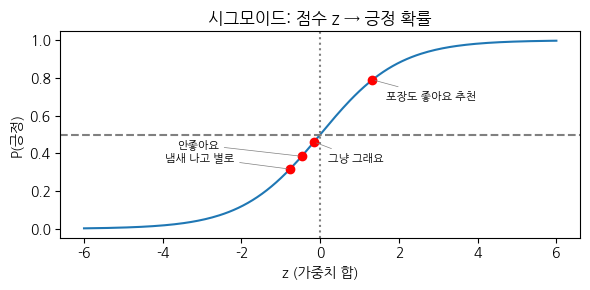

In [25]:
Xt = vec2.transform(test).toarray()
z = Xt @ model.coef_[0] + model.intercept_[0]       # @ = 행렬 곱: 각 문장의 Σ(가중치 × 값) + 절편
p_manual = 1 / (1 + np.exp(-z))                      # 시그모이드
print("z =", z.round(2))
print("직접 계산:", p_manual.round(3), "| 같은가?", np.allclose(p_manual, proba))

zz = np.linspace(-6, 6, 200)
plt.figure(figsize=(6, 3))
plt.plot(zz, 1 / (1 + np.exp(-zz)))
plt.axhline(0.5, color="gray", ls="--"); plt.axvline(0, color="gray", ls=":")
plt.scatter(z, p_manual, color="red", zorder=3)
for k, (zi, pi, t) in enumerate(zip(z, p_manual, test)):
    plt.annotate(t, (zi, pi), textcoords="offset points", xytext=(-90 if k % 2 else 10, 6 if k % 2 else -14),
                 fontsize=8, arrowprops=dict(arrowstyle="-", color="gray", lw=0.5))
plt.title("시그모이드: 점수 z → 긍정 확률"); plt.xlabel("z (가중치 합)"); plt.ylabel("P(긍정)")
plt.tight_layout(); plt.show()

| 문법 | 뜻 |
|---|---|
| `A @ B` | 행렬 곱 (문장마다 Σ 가중치×값) |
| `model.intercept_[0]` | 절편 b |
| `np.exp(x)` | e의 x제곱 |
| `np.allclose(a, b)` | 두 배열이 (반올림 오차 안에서) 같은가 |

> z가 0이면 0.5, 클수록 1, 작을수록 0에 가깝습니다. 확률은 **학습한 패턴과 얼마나 닮았나**이지 '맞을 확률'이 아닙니다. 학습에 없던 `그냥 그래요`는 0.5 근처(애매)입니다.

**워크북에서 쓰는 곳:** 3-4 ai_prob, 3-6 애매 구간

---
## 3.6 비교·평가 (워크북 4)

### 예제 25. 혼동행렬과 정확도·정밀도·재현율 직접 세기
별점 라벨(참고 정답) 10개와 AI 예측 10개를 비교합니다. 쇼핑몰에서는 불만(부정)을 놓치지 않는 것이 중요하므로 **부정**을 기준으로 셉니다.

In [26]:
y_true = ["긍정"]*4 + ["부정"]*6                                                       # 별점 라벨
y_ai   = ["긍정", "긍정", "긍정", "부정", "부정", "부정", "부정", "부정", "긍정", "부정"]   # AI 예측

print(pd.crosstab(pd.Series(y_true, name="별점"), pd.Series(y_ai, name="AI")))         # 혼동행렬

TP = sum(t == "부정" and p == "부정" for t, p in zip(y_true, y_ai))   # 불만을 불만으로
FP = sum(t == "긍정" and p == "부정" for t, p in zip(y_true, y_ai))   # 칭찬인데 불만이라 함
FN = sum(t == "부정" and p == "긍정" for t, p in zip(y_true, y_ai))   # 불만을 놓침
acc = sum(t == p for t, p in zip(y_true, y_ai)) / len(y_true)
print(f"정확도 {acc:.2f} | 부정 정밀도 {TP/(TP+FP):.2f} | 부정 재현율 {TP/(TP+FN):.2f}")

AI  긍정  부정
별점        
긍정   3   1
부정   1   5
정확도 0.80 | 부정 정밀도 0.83 | 부정 재현율 0.83


| 문법 | 뜻 |
|---|---|
| `A and B` | 두 조건 모두 참 |
| `정확도` | 맞은 수 ÷ 전체 |
| `정밀도(부정) = TP ÷ (TP+FP)` | '불만'이라 한 것 중 진짜 불만 |
| `재현율(부정) = TP ÷ (TP+FN)` | 진짜 불만 중 찾아낸 비율 |

**워크북에서 쓰는 곳:** 4-1 혼동행렬·지표

### 예제 26. 일치율의 함정 — 둘 다 틀려도 일치
규칙과 AI가 같은 답을 낸 비율(일치율)은 높아도, 둘이 **같이 틀린** 경우가 섞여 있습니다. scikit-learn 보고서로 지표를 한 번에 확인합니다.

In [27]:
from sklearn.metrics import classification_report
y_rule = ["긍정", "긍정", "부정", "부정", "부정", "부정", "부정", "부정", "긍정", "부정"]   # 규칙 예측
print(classification_report(y_true, y_ai, digits=2, zero_division=0))

agree = sum(a == r for a, r in zip(y_ai, y_rule)) / len(y_ai)
both_wrong = sum(a == r != t for a, r, t in zip(y_ai, y_rule, y_true))
print(f"AI-규칙 일치율 {agree:.2f} — 그중 둘 다 틀린 경우 {both_wrong}건")

              precision    recall  f1-score   support

          긍정       0.75      0.75      0.75         4
          부정       0.83      0.83      0.83         6

    accuracy                           0.80        10
   macro avg       0.79      0.79      0.79        10
weighted avg       0.80      0.80      0.80        10

AI-규칙 일치율 0.90 — 그중 둘 다 틀린 경우 2건


| 문법 | 뜻 |
|---|---|
| `classification_report(정답, 예측)` | 정밀도·재현율·F1·정확도를 한 번에 |
| `a == r != t` | 연쇄 비교: `a == r` 그리고 `r != t` (같은 답인데 정답과 다름) |

> 일치율은 두 방법이 **얼마나 비슷한가**이지 정확도가 아닙니다.

**워크북에서 쓰는 곳:** 4-2 규칙 vs AI, 4-3 불일치 사례

---
## 정리 — 워크북별로 다시 볼 예제
| 워크북 | 대표 코드 | 예제 |
|---|---|---|
| 0 수집 | `read_csv(sep="\t", header=None)`, `drop_duplicates(keep=False)`, `re.search(PII)`, `groupby().sample()`, `hashlib.md5` | 11, 12, 13, 14, 15 |
| 1 정제·탐색 | `.str`, 새 열, `re.sub`, `re.findall` + `Counter`, `groupby().mean()` | 6, 9, 16, 17 |
| 2 규칙 | `sum(w in text ...)`, `def`, 조건 표현식, `.map(rule)` | 5, 8, 18, 19, 20 |
| 3 AI | `TfidfVectorizer`, `fit_transform`/`transform`, `LogisticRegression`, `predict_proba[:, 1]`, `coef_` | 21, 22, 23, 24 |
| 4 평가 | `crosstab`, 정밀도·재현율, `classification_report`, 일치율 | 9, 25, 26 |

➡️ 실습: `Week06_00_감성데이터수집_실습.ipynb` → `Week06_리뷰감성분석_실습.ipynb`